Proyecto: Segmentación de clientes y recomendaciones para marketing
Objetivo del proyecto

Identificar grupos de clientes con características similares mediante K-Means y utilizar los resultados para proponer estrategias de marketing personalizadas.

Ruta de trabajo
1. Preparación del entorno y carga de datos
2. Exploración y limpieza de datos
3. Selección de variables
4. Normalización de los datos
5. Determinación del número óptimo de clusters
6. Aplicación del algoritmo K-Means
7. Visualización e interpretación de los grupos
8. Elaboración de recomendaciones de marketing

Primera etapa. Preparación del notebook
NOTA: Los datos que voy ausar son datos imaginarios, creados solo para la ejecución del presente ejercicio, lo he nombrado 'Mall_Customers'

Paso 1. Importar las bibliotecas

En la primera celda de tu notebook coloca lo siguiente:

In [2]:
# Importar bibliotecas necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración de las gráficas
sns.set_style('whitegrid')

¿Para qué utilizaremos estas bibliotecas?

Biblioteca	                Función
Pandas	                    Cargar y analizar los datos.
NumPy	                    Operaciones numéricas.
Matplotlib	                Crear gráficas.
Seaborn	                    Visualizar datos y clusters.
StandardScaler	            Normalizar las variables.
KMeans	                    Agrupar clientes.
silhouette_score	        Evaluar la calidad de los clusters.

Paso 2. Cargar nuestra base de datos
Vamos a utilizar el conjunto de datos Mall Customers, que contiene información sobre los clientes de un centro comercial.

In [4]:
# Cargar la base de datos

df = pd.read_csv('data/Mall_Customers.csv')

# Mostrar los primeros registros

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,96,Male,48,89,25
1,16,Male,21,27,84
2,31,Female,36,31,77
3,159,Female,30,49,31
4,129,Female,43,29,15


Paso 3. Conocer la estructura de los datos
En la tercera celda:

Esto nos permitirá conocer:

- Cuántos clientes tenemos.
- Cuántas variables contiene la base.
- Qué tipo de información tiene cada columna.
- Si existen valores faltantes.

In [6]:
# Conocer las dimensiones del conjunto de datos

print("Dimensiones de la base de datos:")
# Cuántos clientes hay en el df.
print(df.shape)

# Conocer los tipos de variables
print("\nInformación general:")
df.info()

Dimensiones de la base de datos:
(200, 5)

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


Paso 4. Revisar los datos faltantes y duplicados

En la cuarta celda.

Este paso es importante porque debemos asegurarnos de trabajar con información confiable antes de aplicar el algoritmo.

In [7]:
# Revisar valores faltantes

print("Valores faltantes:")
print(df.isnull().sum())

# Revisar registros duplicados

print("\nRegistros duplicados:")
print(df.duplicated().sum())

Valores faltantes:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Registros duplicados:
0


Paso 5. Analizar estadísticamente los datos

En la quinta celda

Aquí podremos observar los promedios, valores mínimos, máximos y distribución de las variables numéricas.

Por ejemplo, podremos conocer la edad promedio de los clientes, sus ingresos anuales y su puntuación de gasto.

In [8]:
# Obtener estadísticas descriptivas

df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,35.140000,56.340000,47.805000
std,57.879185,9.910676,25.630039,26.889257
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,27.000000,30.750000,24.750000
50%,100.500000,34.000000,57.000000,44.000000
75%,150.250000,42.000000,76.000000,75.250000
max,200.000000,62.000000,109.000000,100.000000


Segunda etapa. Selección y preparación de variables

Paso 6. Seleccionar las variables para la segmentación
Primero debemos decidir qué características utilizaremos para agrupar a los clientes.

En este ejercicio utilizaremos tres variables:

1. Edad (Age).
2. Ingreso anual (Annual Income (k$)).
3. Puntuación de gasto (Spending Score (1-100)).

¿Por qué estas tres? Porque nos permiten analizar quiénes son los clientes, cuánto ingreso tienen y cuál es su comportamiento de consumo.

¿Por qué no incluimos CustomerID?

Porque es solamente un identificador del cliente y no aporta información sobre su comportamiento.

Tampoco incluiremos Gender en esta primera versión, para mantener el ejercicio sencillo y trabajar únicamente con variables numéricas.

In [9]:
# Seleccionar las variables para el análisis

features = df[['Age',
               'Annual Income (k$)',
               'Spending Score (1-100)']]

# Mostrar los primeros registros

features.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,48,89,25
1,21,27,84
2,36,31,77
3,30,49,31
4,43,29,15


Paso 7. Normalizar los datos

Este paso es muy importante.

Las variables tienen escalas diferentes. Por ejemplo, la edad puede estar entre 18 y 62 años, mientras que el ingreso anual tiene otros valores.

Por eso utilizaremos StandardScaler, que permite estandarizar las variables para que ninguna tenga una influencia desproporcionada en el cálculo de distancias, con lo que ya tendremos los datos preparados para aplicar K-Means.

In [ ]:
# Crear el objeto para normalizar los datos
scaler = StandardScaler()

# Aplicar la normalización
scaled_features = scaler.fit_transform(features)

# Mostrar los primeros registros normalizados
scaled_features[:5]

array([[ 1.30084673,  1.27748372, -0.85023648],
       [-1.43032448, -1.14762316,  1.34945448],
       [ 0.08699286, -0.99116465,  1.0884742 ],
       [-0.51993408, -0.28710136, -0.6265391 ],
       [ 0.79507429, -1.0693939 , -1.22306546]])

Tercera etapa. Determinar el número óptimo de clusters

Antes de decidir si utilizaremos 3, 5 o 6 grupos, vamos a evaluar diferentes posibilidades.

Paso 8. Aplicar el método del codo (Elbow Method)

¿Qué buscamos?

Una gráfica en la que la curva disminuye conforme aumentamos los clusters. Buscaremos el punto donde la disminución comienza a ser menos pronunciada.

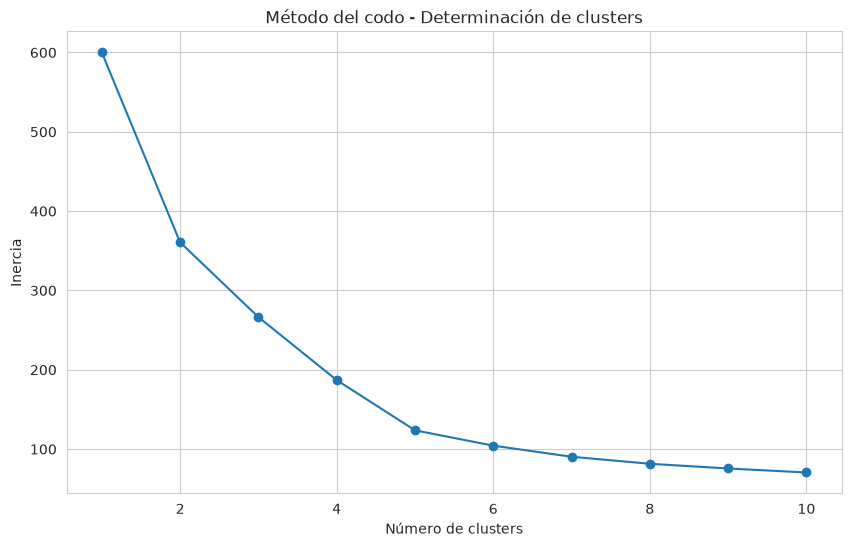

In [11]:
# Método del codo

inertia = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        max_iter=300,
        n_init=10,
        random_state=42
    )

    kmeans.fit(scaled_features)

    inertia.append(kmeans.inertia_)

# Graficar resultados

plt.figure(figsize=(10, 6))

plt.plot(range(1, 11), inertia, marker='o')

plt.title('Método del codo - Determinación de clusters')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')

plt.show()

Paso 9. Evaluar los clusters mediante Silhouette

Ahora utilizaremos otra medida para evaluar qué tan bien separados están los grupos.

Aquí podremos comparar los resultados de 2 a 10 clusters.

Un valor de Silhouette más cercano a 1 generalmente indica grupos mejor separados.

In [12]:
# Evaluar diferentes cantidades de clusters

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        max_iter=300,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(scaled_features)

    score = silhouette_score(scaled_features, labels)

    print(f'Clusters: {k} | Silhouette: {score:.3f}')

Clusters: 2 | Silhouette: 0.350
Clusters: 3 | Silhouette: 0.343
Clusters: 4 | Silhouette: 0.401
Clusters: 5 | Silhouette: 0.465
Clusters: 6 | Silhouette: 0.441
Clusters: 7 | Silhouette: 0.432
Clusters: 8 | Silhouette: 0.409
Clusters: 9 | Silhouette: 0.389
Clusters: 10 | Silhouette: 0.377


Evaluación de tus resultados

Los siguientes resultados del coeficiente Silhouette:

Número de clusters	Silhouette
2	                  0.350
3	                  0.343
4	                  0.401
5	                  0.465
6	                  0.441
7	                  0.432
8	                  0.409
9	                  0.389
10	                  0.377

Usaremos '5' clusters, y Hay dos razones:

1. El método del codo, cuya gráfica aparece en la página 7, muestra una disminución importante de la inercia hasta aproximadamente 5 clusters. Después de ese punto, la curva comienza a estabilizarse.
2. El método Silhouette obtiene su valor más alto con 5 clusters (0.465), lo que indica una mejor separación de los grupos entre las alternativas evaluadas.

Por lo tanto, utilizaremos K=5 para continuar nuestro proyecto.

Cuarta etapa. Aplicación del algoritmo K-Means

Ahora vamos a construir nuestro modelo definitivo.

En una nueva celda de tu notebook coloca:

Paso 10. Entrenar el modelo con 5 clusters

¿Qué estamos haciendo?

- Creamos cinco grupos de clientes.
- Entrenamos el algoritmo K-Means.
- Asignamos cada cliente a un grupo.
- Guardamos el resultado en una nueva columna llamada Cluster.

Los identificadores serán 0, 1, 2, 3 y 4.

In [13]:
# Crear el modelo K-Means con 5 clusters

kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    max_iter=300,
    n_init=10,
    random_state=42
)

# Entrenar el modelo y asignar cada cliente a un grupo

clusters = kmeans.fit_predict(scaled_features)

# Guardar los resultados en el DataFrame

df['Cluster'] = clusters

# Mostrar los primeros registros

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,96,Male,48,89,25,2
1,16,Male,21,27,84,3
2,31,Female,36,31,77,3
3,159,Female,30,49,31,0
4,129,Female,43,29,15,1


Quinta etapa. Analizar las características de cada grupo

Esta es una de las partes más importantes de nuestro proyecto.

No basta con saber que existen cinco grupos. Necesitamos conocer cómo son sus integrantes para que marketing pueda diseñar campañas específicas.

Paso 11. Obtener el perfil de cada cluster

Este código nos dará una tabla con los valores obtenidos al ejecutar tu notebook, Con esta información podremos identificar qué grupos tienen ingresos elevados, cuáles gastan más y cuáles necesitan incentivos para consumir.

In [16]:
# Analizar las características de cada grupo

resumen_clusters = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
}).round(2)

# Cambiar el nombre de la columna de cantidad

resumen_clusters.rename(
    columns={'CustomerID': 'Cantidad de clientes'},
    inplace=True
)

# Mostrar resultados

print(resumen_clusters)

           Age  Annual Income (k$)  Spending Score (1-100)  \
Cluster                                                      
0        31.16               59.38                   39.02   
1        48.28               30.94                   20.31   
2        44.18               89.71                   19.46   
3        25.56               26.08                   77.86   
4        31.59               79.00                   79.54   

         Cantidad de clientes  
Cluster                        
0                          61  
1                          36  
2                          28  
3                          36  
4                          39  


/tmp/ipykernel_5255/2080781298.py:12: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  resumen_clusters.rename(


Visualizar los cinco grupos

Paso 12. Crear la gráfica de segmentación

Esta gráfica nos ayudará a observar cómo se distribuyen los clientes según sus ingresos y su puntuación de gasto.

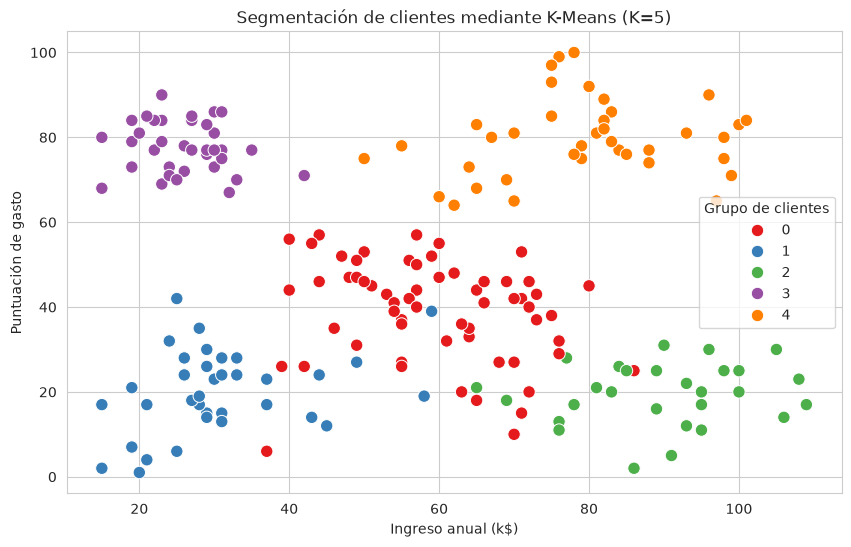

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=80
)

plt.title('Segmentación de clientes mediante K-Means (K=5)')
plt.xlabel('Ingreso anual (k$)')
plt.ylabel('Puntuación de gasto')
plt.legend(title='Grupo de clientes')

plt.show()

Visualizar cuántos clientes hay en cada grupo

Paso 13. Distribución de clientes por cluster

Esto permitirá conocer qué segmentos concentran más clientes y cuáles representan grupos más pequeños.

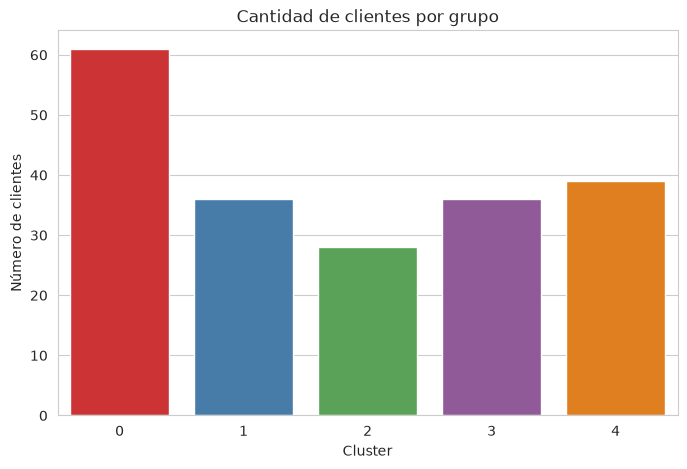

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Cluster',
    hue='Cluster',
    palette='Set1',
    legend=False
)

plt.title('Cantidad de clientes por grupo')
plt.xlabel('Cluster')
plt.ylabel('Número de clientes')

plt.show()

¿Qué haremos con estos resultados?

Convertir al análisis de datos en una herramienta para el departamento de marketing.
Nuestro objetivo final

1. Identificar los cinco segmentos de clientes.
2. Describir las características de cada segmento.
3. Asignar un perfil comercial a cada grupo.
4. Proponer campañas específicas para cada perfil.
5. Elaborar el reporte formal de recomendaciones de al menos 300 palabras.

Con estos resultados vamos a hacer algo muy interesante: pondremos nombre a cada segmento, por ejemplo, clientes de alto valor, clientes potenciales, consumidores moderados, etc., siempre de acuerdo con sus características reales.

Así podremos presentar al departamento de marketing no solamente cinco grupos de números, sino cinco perfiles de clientes con recomendaciones concretas para mejorar las campañas.

Ahora vamos a interpretar estos resultados.

Cluster 0. Clientes de consumo moderado
61 clientes · 30.5% del total
- Edad promedio: 31 años.
- Ingreso promedio: 59.38 k$.
- Gasto promedio: 39.02.
Recomendación: promociones personalizadas, descuentos por compras recurrentes y programas de fidelización.

Cluster 1. Clientes de bajo ingreso y bajo gasto
36 clientes · 18% del total
- Edad promedio: 48 años.
- Ingreso promedio: 30.94 k$.
- Gasto promedio: 20.31.
Recomendación: ofertas económicas, descuentos y paquetes accesibles.

Cluster 2. Clientes de alto ingreso y bajo gasto
28 clientes · 14% del total
- Edad promedio: 44 años.
- Ingreso promedio: 89.71 k$.
- Gasto promedio: 19.46.
Recomendación: campañas exclusivas, beneficios especiales y promociones que incentiven el consumo.

Cluster 3. Clientes jóvenes con alto nivel de gasto
36 clientes · 18% del total
- Edad promedio: 26 años.
- Ingreso promedio: 26.08 k$.
- Gasto promedio: 77.86.
Recomendación: promociones digitales, descuentos por temporada y campañas en redes sociales.

Cluster 4. Clientes de alto valor comercial
39 clientes · 19.5% del total
- Edad promedio: 32 años.
- Ingreso promedio: 79 k$.
- Gasto promedio: 79.54.
Recomendación: programas VIP, lanzamientos exclusivos, recompensas y beneficios de fidelidad.



Estos nombres son perfiles comerciales propuestos a partir de los promedios; no son categorías generadas automáticamente por K-Means.

Sexta etapa. Construcción de perfiles comerciales y recomendaciones.

Primero vamos a crear una tabla que muestre el porcentaje que representa cada grupo dentro del total de clientes.

Paso 14. Calcular la participación de cada segmento

Esto nos permitirá conocer qué porcentaje de la población representa cada segmento.

In [18]:
# Calcular la cantidad de clientes por cluster

cantidad_clientes = df['Cluster'].value_counts().sort_index()

# Calcular el porcentaje de participación

porcentaje_clientes = (cantidad_clientes / len(df)) * 100

# Crear tabla de participación

participacion = pd.DataFrame({
    'Cantidad de clientes': cantidad_clientes,
    'Porcentaje (%)': porcentaje_clientes.round(2)
})

print(participacion)

         Cantidad de clientes  Porcentaje (%)
Cluster                                      
0                          61            30.5
1                          36            18.0
2                          28            14.0
3                          36            18.0
4                          39            19.5


Paso 15. Asignar nombres comerciales a los clusters

Ahora vamos a sustituir los identificadores numéricos por nombres que sean más fáciles de interpretar para el departamento de marketing.

Ahora cada cliente tendrá asignado un perfil comercial que facilitará la interpretación de los resultados.

In [19]:
# Crear diccionario de perfiles comerciales

nombres_clusters = {
    0: 'Consumo moderado',
    1: 'Bajo ingreso y bajo gasto',
    2: 'Alto ingreso y bajo gasto',
    3: 'Jovenes con alto gasto',
    4: 'Clientes de alto valor'
}

# Crear nueva columna con los nombres

df['Perfil'] = df['Cluster'].map(nombres_clusters)

# Mostrar los primeros registros

df[['CustomerID', 'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)',
    'Cluster', 'Perfil']].head(10)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster,Perfil
0,96,48,89,25,2,Alto ingreso y bajo gasto
1,16,21,27,84,3,Jovenes con alto gasto
2,31,36,31,77,3,Jovenes con alto gasto
3,159,30,49,31,0,Consumo moderado
4,129,43,29,15,1,Bajo ingreso y bajo gasto
5,116,45,31,28,1,Bajo ingreso y bajo gasto
6,70,25,76,99,4,Clientes de alto valor
7,171,22,64,33,0,Consumo moderado
8,175,31,71,42,0,Consumo moderado
9,46,32,98,80,4,Clientes de alto valor


Paso 16. Crear una tabla final para marketing

Esta será una de las tablas más importantes de nuestro proyecto, porque resume los perfiles comerciales que el equipo de marketing deberá considerar.

In [20]:
# Resumen comercial de los segmentos

reporte_marketing = df.groupby('Perfil').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean'
}).round(2)

reporte_marketing.rename(columns={
    'CustomerID': 'Total de clientes',
    'Age': 'Edad promedio',
    'Annual Income (k$)': 'Ingreso promedio',
    'Spending Score (1-100)': 'Gasto promedio'
}, inplace=True)

print(reporte_marketing)

                           Total de clientes  Edad promedio  Ingreso promedio  \
Perfil                                                                          
Alto ingreso y bajo gasto                 28          44.18             89.71   
Bajo ingreso y bajo gasto                 36          48.28             30.94   
Clientes de alto valor                    39          31.59             79.00   
Consumo moderado                          61          31.16             59.38   
Jovenes con alto gasto                    36          25.56             26.08   

                           Gasto promedio  
Perfil                                     
Alto ingreso y bajo gasto           19.46  
Bajo ingreso y bajo gasto           20.31  
Clientes de alto valor              79.54  
Consumo moderado                    39.02  
Jovenes con alto gasto              77.86  


/tmp/ipykernel_5255/1170778974.py:10: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  reporte_marketing.rename(columns={


La parte más importante del proyecto: convertir los resultados del análisis en decisiones de marketing.

Vamos a agregar una séptima etapa a tu notebook.

Séptima etapa. Diseño de estrategias de marketing

Paso 17. Crear una tabla de recomendaciones comerciales

¿Qué conseguiremos?

Una tabla que reúna las características de los clientes y las estrategias que recomendamos para cada grupo.

Así, el departamento de marketing podrá consultar tanto los datos como las acciones propuestas.

In [21]:
# Crear estrategias de marketing por segmento

estrategias = {
    'Consumo moderado':
        'Promociones personalizadas, descuentos por compras '
        'recurrentes y programas de fidelizacion',

    'Bajo ingreso y bajo gasto':
        'Ofertas economicas, paquetes accesibles y descuentos especiales',

    'Alto ingreso y bajo gasto':
        'Campañas exclusivas, beneficios especiales y promociones '
        'para incentivar el consumo',

    'Jovenes con alto gasto':
        'Campañas digitales, redes sociales, tendencias y descuentos '
        'por temporada',

    'Clientes de alto valor':
        'Programas VIP, recompensas, lanzamientos exclusivos '
        'y beneficios de fidelidad'
}

# Incorporar las estrategias a la tabla comercial

reporte_marketing['Estrategia recomendada'] = (
    reporte_marketing.index.map(estrategias)
)

# Mostrar el resultado final

reporte_marketing

,Total de clientes,Edad promedio,Ingreso promedio,Gasto promedio,Estrategia recomendada
Perfil,,,,,
Alto ingreso y bajo gasto,28,44.18,89.71,19.46,"Campañas exclusivas, beneficios especiales y p..."
Bajo ingreso y bajo gasto,36,48.28,30.94,20.31,"Ofertas economicas, paquetes accesibles y desc..."
Clientes de alto valor,39,31.59,79.00,79.54,"Programas VIP, recompensas, lanzamientos exclu..."
Consumo moderado,61,31.16,59.38,39.02,"Promociones personalizadas, descuentos por com..."
Jovenes con alto gasto,36,25.56,26.08,77.86,"Campañas digitales, redes sociales, tendencias..."


Paso 18. Visualizar las estrategias por segmento

También vamos a generar una gráfica que permita comparar el potencial de gasto de los diferentes grupos.

Esta gráfica será útil para presentar visualmente las diferencias entre los cinco segmentos.

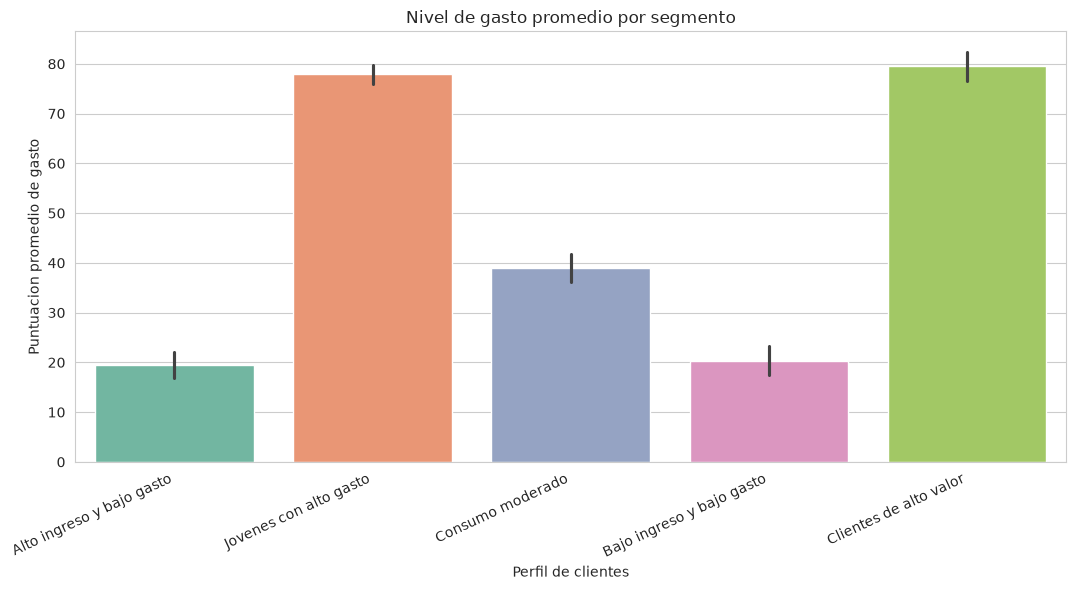

In [22]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df,
    x='Perfil',
    y='Spending Score (1-100)',
    hue='Perfil',
    palette='Set2',
    legend=False
)

plt.title('Nivel de gasto promedio por segmento')
plt.xlabel('Perfil de clientes')
plt.ylabel('Puntuacion promedio de gasto')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()

Elaboración del reporte formal

Esta será nuestra octava y última etapa.

El reporte deberá tener un mínimo de 300 palabras y estará dirigido formalmente al departamento de marketing.

Te propongo esta estructura:

1. Introducción: objetivo del análisis y metodología K-Means.
2. Resultados: descripción de los cinco segmentos identificados.
3. Recomendaciones: campañas específicas para cada perfil.
4. Conclusiones: beneficios esperados de implementar una estrategia de marketing segmentada.

También incluiremos una recomendación general: no utilizar la misma campaña para todos los clientes, sino adaptar los mensajes, promociones y beneficios a las características de cada segmento.

Aparece la gráfica que compara el nivel de gasto de los cinco perfiles.

Hay un resultado importante: los clientes de alto valor tienen una puntuación promedio de gasto de 79.54, mientras que los clientes de alto ingreso y bajo gasto presentan 19.46. Esta diferencia es especialmente interesante para orientar las campañas.

Última etapa: elaborar el reporte para Marketing

REPORTE DE RECOMENDACIONES PARA EL DEPARTAMENTO DE MARKETING

Proyecto: Segmentación de clientes mediante aprendizaje no supervisado  
Metodología: Algoritmo K-Means  
Población analizada: 200 clientes  
Destinatario: Departamento de Marketing

1. Introducción

El presente reporte tiene como objetivo presentar los resultados del análisis de segmentación de clientes realizado mediante el algoritmo K-Means, una técnica de aprendizaje no supervisado que permite identificar grupos de usuarios con características similares.

Para este ejercicio se utilizaron datos de edad, ingreso anual y puntuación de gasto de 200 clientes. Después de preparar y normalizar la información, se evaluaron diferentes cantidades de clusters mediante el método del codo y el coeficiente Silhouette. Se determinó que cinco grupos representan una alternativa adecuada para continuar con el análisis, obteniendo un coeficiente Silhouette de 0.465.

2. Resultados de la segmentación

El análisis permitió identificar cinco perfiles comerciales:

- Clientes de consumo moderado: representan 30.5% de los clientes, con una edad promedio de 31 años y una puntuación de gasto de 39.02. Constituyen el segmento más numeroso.
- Clientes de bajo ingreso y bajo gasto: representan 18%, con una edad promedio de 48 años y una puntuación de gasto de 20.31.
- Clientes de alto ingreso y bajo gasto: representan 14%, con una edad promedio de 44 años y una puntuación de gasto de 19.46. Este grupo presenta una oportunidad para incentivar un mayor consumo.
- Jóvenes con alto gasto: representan 18%, con una edad promedio de 26 años y una puntuación de gasto de 77.86.
- Clientes de alto valor comercial: representan 19.5%, con una edad promedio de 32 años y una puntuación de gasto de 79.54. Este segmento presenta el nivel de gasto más elevado.

3. Recomendaciones para el departamento de Marketing

Se recomienda implementar campañas diferenciadas de acuerdo con las características de cada segmento.

Para los clientes de consumo moderado, se sugieren promociones personalizadas, descuentos por compras recurrentes y programas de fidelización que permitan incrementar su frecuencia de consumo.

Para los clientes de bajo ingreso y bajo gasto, se recomienda desarrollar ofertas económicas, paquetes accesibles y descuentos especiales que faciliten su participación en las promociones comerciales.

En el caso de los clientes de alto ingreso y bajo gasto, se propone implementar campañas exclusivas, beneficios especiales y promociones personalizadas que permitan despertar su interés y aumentar su participación en las compras.

Para los jóvenes con alto gasto, se recomienda utilizar estrategias digitales, redes sociales, promociones de temporada y campañas relacionadas con tendencias de consumo.

Finalmente, para los clientes de alto valor comercial, se propone implementar programas VIP, recompensas, lanzamientos exclusivos y beneficios de fidelidad con el propósito de fortalecer su relación con la empresa.

4. Conclusiones

Los resultados demuestran que la segmentación mediante K-Means constituye una herramienta útil para comprender las diferencias entre los clientes y diseñar estrategias comerciales más específicas.

Se recomienda al departamento de marketing evitar la aplicación de campañas generalizadas y adoptar un enfoque de comunicación personalizada. Asimismo, es conveniente evaluar periódicamente los resultados de las campañas mediante indicadores como frecuencia de compra, tasa de conversión, respuesta a promociones y retención de clientes.

La implementación de estas recomendaciones permitirá aprovechar mejor los recursos de marketing, identificar oportunidades de crecimiento y fortalecer la relación con los diferentes perfiles de consumidores.